# 04 - Building our own injection forecast from weather

Notebook 03 found that "actual vs 5-year average" doesn't predict the price reaction, and that prices move **before** the report. The likely reason is that traders forecast each week's number from the weather, so the market already expects most of the gap from normal.

The fix is to do what gas desks do: **forecast the weekly storage change from weather**, then define

> **surprise = actual change − our forecast**

If this is closer to what the market expects, it should explain Thursday's price move better than the 5-year proxy.

**The physics:** most US winter gas demand is space heating, and heating demand rises roughly linearly as the temperature falls below about 65°F. Summer demand is mostly power stations burning gas to run air conditioning. The standard way to measure this is with **degree days**:
- **HDD (heating degree days)** = max(0, 65 − average daily temperature in °F)
- **CDD (cooling degree days)** = max(0, average daily temperature in °F − 65)

A week of 7 days at 35°F is 7 × 30 = 210 HDD.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gasdata import CITIES, expiry_and_roll_days, fetch_degree_days, rolling_forecast, surprise_regression
from style import BLUE, GRAY, INK2, ORANGE  # shared project chart style

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
START = "2015-01-01"  # same sample as notebook 03

storage = pd.read_csv(DATA_DIR / "storage_features.csv", index_col="period", parse_dates=["period", "report_date"])
prices = pd.read_csv(DATA_DIR / "prices_daily.csv", index_col="Date", parse_dates=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 1. Weather data
Free data comes from **Open-Meteo**, which serves ERA5 reanalysis: a gridded reconstruction of past weather from observations, with no API key needed. The code pulls daily mean temperatures for 17 large US cities and weights each by metro population, giving one national HDD and CDD number per day.

**A caveat:** professional desks use *gas-weighted* degree days, weighting each region by how much gas it actually burns for heating. Population weighting is a reasonable free approximation. NOAA's Climate Prediction Center also publishes official population-weighted degree days for free (`ftp.cpc.ncep.noaa.gov/htdocs/degree_days/`) if you want to compare.

Each storage week runs **Saturday to Friday**. The weather for that week is fully known by the following Thursday's release, so using it involves no look-ahead.

In [2]:
daily_dd = fetch_degree_days("2010-01-01", storage.index[-1].strftime("%Y-%m-%d"))
daily_dd.to_csv(DATA_DIR / "degree_days_daily.csv")

weekly_dd = daily_dd.resample("W-FRI").sum()  # Sat-Fri weeks, labelled by the Friday = EIA week-ending date
df = storage.join(weekly_dd, how="inner")
print(f"{len(CITIES)} cities, {len(daily_dd):,} days -> {len(weekly_dd)} weeks")
df[["change_bcf", "hdd", "cdd"]].tail()

17 cities, 6,140 days -> 878 weeks


,change_bcf,hdd,cdd
period,,,
2026-09-25,64.0,14.709902,43.498305
2026-10-02,85.0,10.741659,43.330152
2026-10-09,67.0,21.041570,44.109723
2026-10-16,77.0,17.360839,36.055219
2026-10-23,80.0,54.701070,16.489920


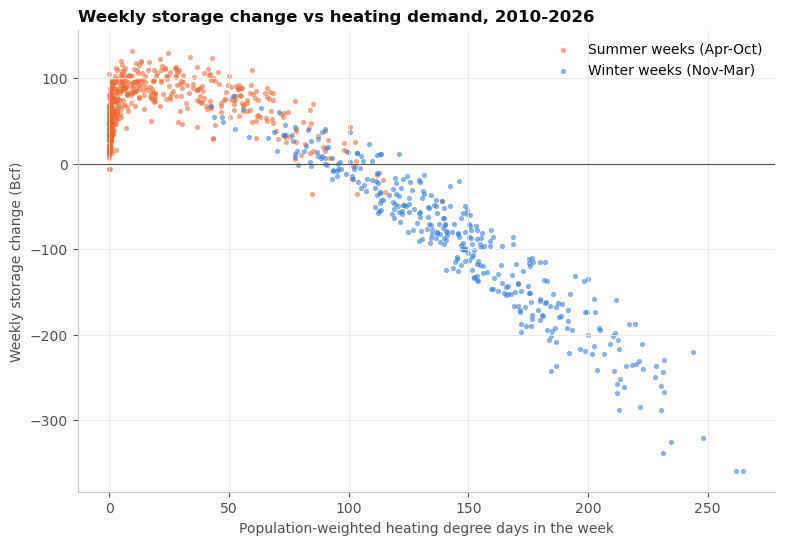

Correlation of weekly change with HDD: -0.91


In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
winter = df.index.month.isin([11, 12, 1, 2, 3])
ax.scatter(df.loc[~winter, "hdd"], df.loc[~winter, "change_bcf"], s=14, color=ORANGE, alpha=0.55, lw=0, label="Summer weeks (Apr-Oct)")
ax.scatter(df.loc[winter, "hdd"], df.loc[winter, "change_bcf"], s=14, color=BLUE, alpha=0.55, lw=0, label="Winter weeks (Nov-Mar)")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Weekly storage change vs heating demand, 2010-2026")
ax.set_xlabel("Population-weighted heating degree days in the week")
ax.set_ylabel("Weekly storage change (Bcf)")
ax.legend(loc="upper right")
save(fig, "08_storage_change_vs_hdd")
plt.show()

print(f"Correlation of weekly change with HDD: {df['change_bcf'].corr(df['hdd']):+.2f}")

## 2. The forecast models
Three candidates, all forecasting one week at a time:

| Model | Forecast of this week's change | Idea |
|---|---|---|
| **5-year average** | average change for this week over the previous 5 years | the proxy from notebook 03; ignores this week's weather |
| **Weather regression** | a + b·HDD + c·CDD | demand depends on temperature |
| **Week-on-week** | last week's change + b·ΔHDD + c·ΔCDD | start from last week's actual, then adjust for how much colder or warmer this week is |

The week-on-week model is how many analysts think about it. Last week's number already reflects current production, LNG exports and other slow-moving factors, so only the change in weather needs explaining.

**No look-ahead:** coefficients are refitted every week using only the previous **3 years** (156 weeks). The forecast for each week uses only information available before that week's release. The rolling window also lets the model adapt as the market changes, for example as LNG exports grow.

In [4]:
WINDOW = 156  # weeks of history used for each fit

df["prev_change"] = df["change_bcf"].shift(1)
df["d_change"] = df["change_bcf"] - df["prev_change"]
df["d_hdd"], df["d_cdd"] = df["hdd"].diff(), df["cdd"].diff()


df["fc_5y_avg"] = df["change_5y_avg"]
df["fc_weather"] = rolling_forecast(df, "change_bcf", ["hdd", "cdd"], WINDOW)  # see gasdata.py
df["fc_week_on_week"] = df["prev_change"] + rolling_forecast(df, "d_change", ["d_hdd", "d_cdd"], WINDOW)

MODELS = {"5-year average": "fc_5y_avg", "Weather regression": "fc_weather", "Week-on-week": "fc_week_on_week"}
test = df.loc[START:].dropna(subset=list(MODELS.values()) + ["change_bcf"])

scores = pd.DataFrame({
    name: {
        "MAE (Bcf)": (test["change_bcf"] - test[col]).abs().mean(),
        "RMSE (Bcf)": np.sqrt(((test["change_bcf"] - test[col]) ** 2).mean()),
        "Bias (Bcf)": (test["change_bcf"] - test[col]).mean(),
    }
    for name, col in MODELS.items()
}).T
print(f"Out-of-sample, {test.index[0].date()} to {test.index[-1].date()} ({len(test)} weeks)")
scores.round(1)

Out-of-sample, 2015-01-02 to 2026-10-23 (615 weeks)


,MAE (Bcf),RMSE (Bcf),Bias (Bcf)
5-year average,30.7,44.5,0.0
Weather regression,20.1,25.0,-1.6
Week-on-week,17.1,22.4,-0.2


**How to read this:** MAE is the average size of the forecast miss in Bcf. For scale, a typical weekly change is somewhere between -300 and +120 Bcf, and the market usually treats a miss of about 5-10 Bcf against consensus as a meaningful surprise. Bias shows whether a model is consistently too high or too low.

The next cell picks the model with the lowest MAE. It also measures **how much of the 5-year "surprise" was predictable from weather** before the release. That's the direct test of notebook 03's explanation.

Best model: Week-on-week
77% of the variation in the 5-year 'surprise' was predictable from weather before the release


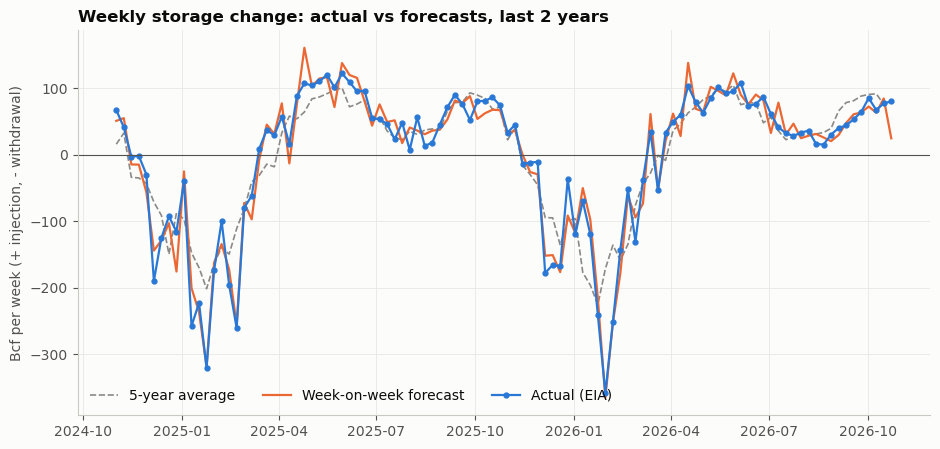

In [5]:
best_name = scores["MAE (Bcf)"].idxmin()
best_col = MODELS[best_name]
df["surprise_model"] = df["change_bcf"] - df[best_col]

expected_gap = (test[best_col] - test["fc_5y_avg"])  # what weather told you about the gap from normal
r2_predictable = test["surprise_bcf"].corr(expected_gap) ** 2
print(f"Best model: {best_name}")
print(f"{r2_predictable:.0%} of the variation in the 5-year 'surprise' was predictable from weather before the release")

df.to_csv(DATA_DIR / "storage_model.csv")

recent = df.iloc[-104:]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(recent.index, recent["fc_5y_avg"], color=GRAY, ls="--", lw=1.2, label="5-year average")
ax.plot(recent.index, recent[best_col], color=ORANGE, lw=1.6, label=f"{best_name} forecast")
ax.plot(recent.index, recent["change_bcf"], color=BLUE, lw=1.6, marker="o", ms=3.5, label="Actual (EIA)")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Weekly storage change: actual vs forecasts, last 2 years")
ax.set_ylabel("Bcf per week (+ injection, - withdrawal)")
ax.legend(loc="lower left", ncol=3)
save(fig, "09_forecast_vs_actual")
plt.show()

## 3. Does the better surprise explain the price reaction?
This repeats notebook 03's test with the new surprise: Thursday's Henry Hub return (Wednesday close to Thursday close) regressed on each surprise measure, with contract expiry and roll days excluded as before.

If the market trades the gap between the actual number and a weather-based expectation, the weather-model surprise should show a **more negative slope, a higher R² and a higher hit rate** than the 5-year proxy.

In [6]:
returns = np.log(prices).diff().loc[START:].dropna(how="all")
trading_days = returns.index
excluded_days = pd.DatetimeIndex(np.concatenate(expiry_and_roll_days(trading_days)))

events = df.loc[START:, ["report_date", "surprise_bcf", "surprise_model"]].dropna()
events = events[events["report_date"].isin(trading_days) & ~events["report_date"].isin(excluded_days)]
events["thu_ret"] = returns["henry_hub"].reindex(events["report_date"]).to_numpy() * 100
winter = events["report_date"].dt.month.isin([11, 12, 1, 2, 3])

comparison = pd.DataFrame({
    "5-year proxy, all": surprise_regression(events, "surprise_bcf"),
    "Weather model, all": surprise_regression(events, "surprise_model"),
    "Weather model, winter": surprise_regression(events[winter], "surprise_model"),
    "Weather model, summer": surprise_regression(events[~winter], "surprise_model"),
}).T
comparison.round(3)

,n,slope_%_per_10bcf,t_stat,p_value,r2,hit_rate
"5-year proxy, all",525.0,0.002,0.058,0.954,0.000,0.526
"Weather model, all",525.0,-0.151,-2.283,0.022,0.009,0.541
"Weather model, winter",210.0,-0.053,-0.604,0.546,0.001,0.538
"Weather model, summer",315.0,-0.267,-2.647,0.008,0.024,0.543


**Quintile view:** reports are sorted into five equal groups, from most bullish (actual far below forecast) to most bearish (actual far above). The chart shows the average Thursday return for each group. If the surprise works, the bars should **step down from left to right**. Error bars are 95% confidence intervals.

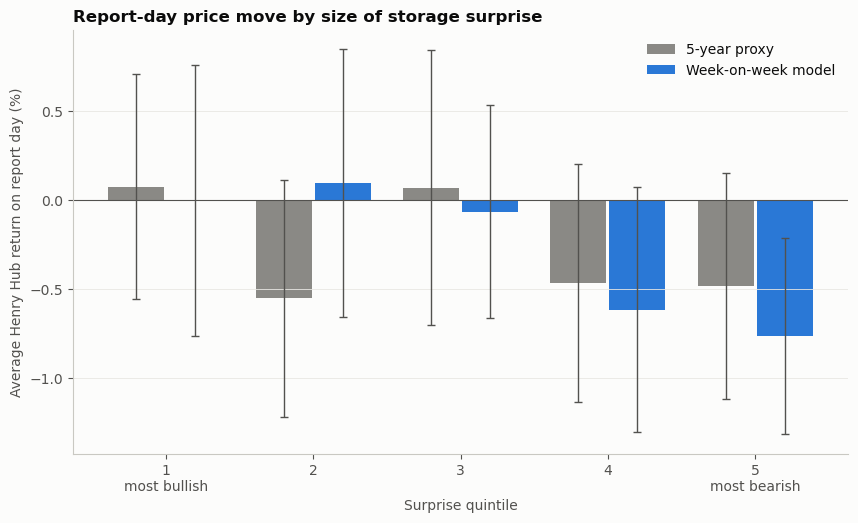

,surprise_model,thu_ret
surprise_model,,
0,-31.47,-0.00
1,-11.27,0.10
2,0.10,-0.07
3,10.17,-0.61
4,30.05,-0.76


In [7]:
labels = ["1\nmost bullish", "2", "3", "4", "5\nmost bearish"]
x = np.arange(5)
w = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (col, name, color) in enumerate([("surprise_bcf", "5-year proxy", GRAY), ("surprise_model", f"{best_name} model", BLUE)]):
    q = pd.qcut(events[col], 5, labels=False)
    grp = events.groupby(q)["thu_ret"]
    mean, ci = grp.mean(), 1.96 * grp.std() / np.sqrt(grp.count())
    ax.bar(x + (i - 0.5) * (w + 0.02), mean, w, yerr=ci, color=color, label=name,
           error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x, labels)
ax.set_xlabel("Surprise quintile")
ax.set_ylabel("Average Henry Hub return on report day (%)")
ax.set_title("Report-day price move by size of storage surprise")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
save(fig, "10_return_by_surprise_quintile")
plt.show()

events.groupby(pd.qcut(events["surprise_model"], 5, labels=False))[["surprise_model", "thu_ret"]].mean().round(2)

## Findings

**1. Weather explains most of the weekly storage change.** Weekly change and HDD have a correlation of -0.91.
- Out of sample since 2015, the week-on-week model's average miss is **17 Bcf**, against **31 Bcf** for the 5-year average. That's about 45% smaller.

**2. Notebook 03's explanation holds up.** About **77% of the variation in the 5-year "surprise" was predictable from weather** before the report came out. Most of what looked like a surprise was already expected.

**3. A surprise measured against the weather model does help explain the price reaction.**
- Slope: -0.15% per 10 Bcf, p ≈ 0.02. The 5-year proxy gave about zero.
- Hit rate: 54%, against 52.5% for the proxy.
- The quintile chart steps down as expected: the two most bearish groups average about -0.6% to -0.8% on report day.
- **The effect is asymmetric:** bearish surprises move the price, but bullish ones barely do.

**4. The effect is still small.** R² is about 1%: the surprise explains about 1% of Thursday's move, and the rest is mostly changes in weather forecasts. It's also concentrated in **summer** (p ≈ 0.008). In winter, the market cares more about next week's weather than about last week's storage.

**Why the model still lags the market:** our average miss is about 17 Bcf, while professional consensus forecasts typically miss by single digits. They use gas-weighted degree days and daily pipeline flow data, and they adjust for holidays, LNG feedgas, wind and solar output, and production changes. The market reacts to the gap from *their* number, so our surprise is still a noisy measure of the real one.

**For trading:**
- This is a real effect, but too small and noisy to trade a CFD on by itself after spreads and slippage.
- The bigger lesson is the method: **the market reacts to the gap between the actual number and what it expected, not the gap from normal.** Weather explains most of the storage number, so weather forecasts are what really move gas between reports.
- The same logic applies to oil inventories, CPI for gold, and any other scheduled data release.

**Possible model improvements:**
- **Shoulder months:** heating demand is flat below about 50 HDD (see chart 08), so a straight line overstates the effect of the first cold weeks. On 23 Oct 2026 the model forecast about +25 Bcf against an actual +80. Adding a separate term for HDD above a threshold should fix this.
- **Holiday weeks:** add a flag for Thanksgiving and Christmas weeks, when industrial demand falls.
- **Gas-weighted degree days:** NOAA's Climate Prediction Center publishes them, and they match where gas is actually burned more closely than population does.